# Stylometric Analysis of Genre in Shakespearean Plays
### Sian Phillips
### Data 400

In this project, I wanted to see if I could use data analysis tools that are designed to solve matters of author attribution to identify whether or not there are consistant stylometric differences between Shakespeare plays of different genres. Specifically I wanted to find out if there was a certain metric that was able to accurately classify random Shakespeare plays when trained on the rest. 

In [577]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /Users/sianp/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In order to do simple testing, I pulled out 2 or 3 random play from each genre and put them into 7 individual test cases.

In [580]:
plays = {
    'Comedy': ['AllsWellThatEndsWell', 'ComedyOfErrors', 'Cymbeline', 'LovesLaboursLost', 'MerryWivesOfWindsor', 'MerchantOfVenice', 'MidsummerNightsDream', 'MuchAdoAboutNothing', 'PericlesPrinceOfTyre', 'Tempest', 'TroilusAndCressida', 'TwelfthNight', 'WintersTale', 'TwoGentlemenOfVerona'],
    'History': ['HenryIV1', 'HenryV', 'HenryVI1', 'HenryVIII', 'KingJohn', 'RichardIII', 'HenryVI2', 'HenryVI3', 'KingLear'],
    'Tragedy': ['Coriolanus', 'Hamlet', 'Othello', 'RomeoAndJuliet', 'TimonOfAthens', 'TitusAndronicus', 'KingLear', 'AntonyAndCleopatra'],
    'Test1': ['AsYouLikeIt'], 
    'Test2': ['MeasureForMeasure'], 
    'Test3': ['TamingOfTheShrew'],
    'Test4': ['HenryIV2'], 
    'Test5': ['RichardII'],
    'Test6': ['JuliusCaesar'], 
    'Test7': ['Macbeth']
}

In [582]:
# A function that compiles all of the text files associated with a single genre into a single string
def read_files_into_string(filenames):
    strings = []
    for filename in filenames:
        with open(f'data/{filename}.txt', 'r') as f:
            strings.append(f.read())
    return '\n'.join(strings)

In [584]:
play_by_genre = {}
for genre, files in plays.items():
    play_by_genre[genre] = read_files_into_string(files)

In [586]:
for genre in plays:
    print(play_by_genre[genre][:100])

ACT I
SCENE I. Rousillon. The COUNT's palace.

Enter BERTRAM, the COUNTESS of Rousillon, HELENA, and
ACT I
SCENE I. London. The palace.

Enter KING HENRY, LORD JOHN OF LANCASTER, the EARL of WESTMORELA
ACT I
SCENE I. Rome. A street.

Enter a company of mutinous Citizens, with staves, clubs, and other 
ACT I
SCENE I. Orchard of Oliver's house.

Enter ORLANDO and ADAM
ORLANDO
As I remember, Adam, it wa
ACT I
SCENE I. An apartment in the DUKE'S palace.

Enter DUKE VINCENTIO, ESCALUS, Lords and Attendan
SCENE I. Before an alehouse on a heath.

Enter Hostess and SLY
SLY
I'll pheeze you, in faith.
Hostes
None

Warkworth. Before the castle

Enter RUMOUR, painted full of tongues
RUMOUR
Open your ears; for
ACT I
SCENE I. London. KING RICHARD II's palace.

Enter KING RICHARD II, JOHN OF GAUNT, with other N
ACT I
SCENE I. Rome. A street.

Enter FLAVIUS, MARULLUS, and certain Commoners
FLAVIUS
Hence! home, 
ACT I
SCENE I. A desert place.

Thunder and lightning. Enter three Witches
First Witch
When

## First Method of Testing for Stylometric Differences: Mendenhall’s Characteristic Curves of Composition
T. C. Mendenhall claimed that an author's stylistic signature could be found by measuring how often they used words of different lengths. This metric is not very sophisticated but it is one of the first attempts at stylometry.

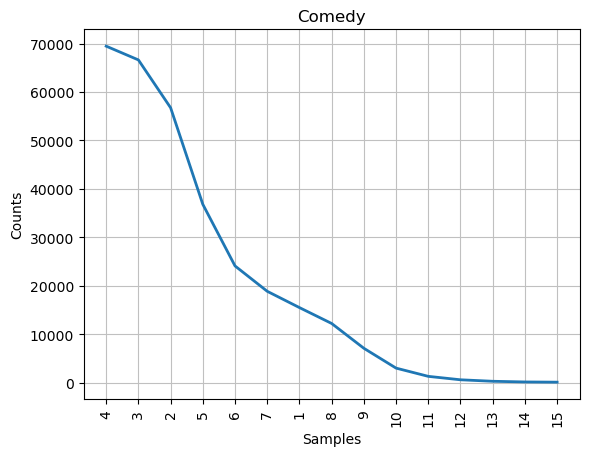

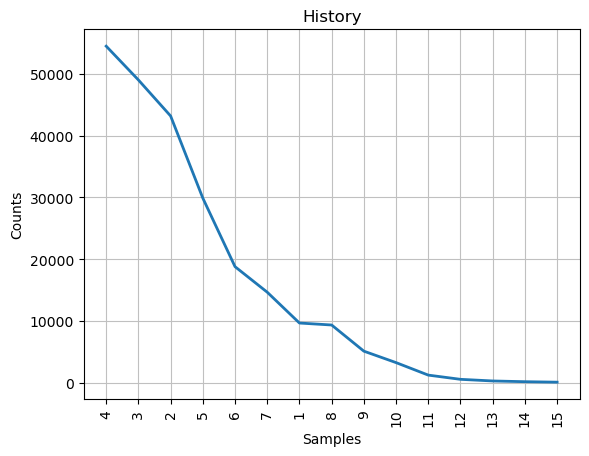

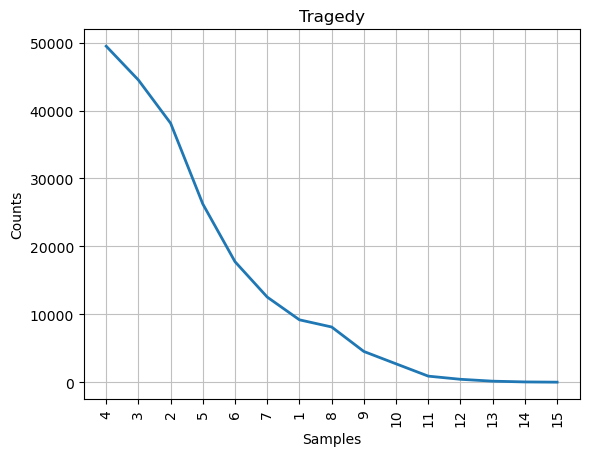

In [589]:
import matplotlib.pyplot as plt


genres = ("Comedy", "History", "Tragedy")

# Transform the authors' corpora into lists of word tokens
play_by_genre_tokens = {}
play_by_genre_length_distributions = {}
for genre in genres:
    tokens = nltk.word_tokenize(play_by_genre[genre])

    # Filter out punctuation
    play_by_genre_tokens[genre] = ([token for token in tokens
                                            if any(c.isalpha() for c in token)])

    # Get a distribution of token lengths
    token_lengths = [len(token) for token in play_by_genre_tokens[genre]]
    play_by_genre_length_distributions[genre] = nltk.FreqDist(token_lengths)
    plt.figure()
    play_by_genre_length_distributions[genre].plot(15, title=genre)



The main noticable distinction is that the curve is much smoother for comedy than the other genres. This can likely be explained by the fact that we have 14 comedies and only 8 tragedies and 8 histories. Shakespeare's characteristic curve seems fairly constant regardless of genre, but to further compare differences I plotted the relative frequency on one graph.

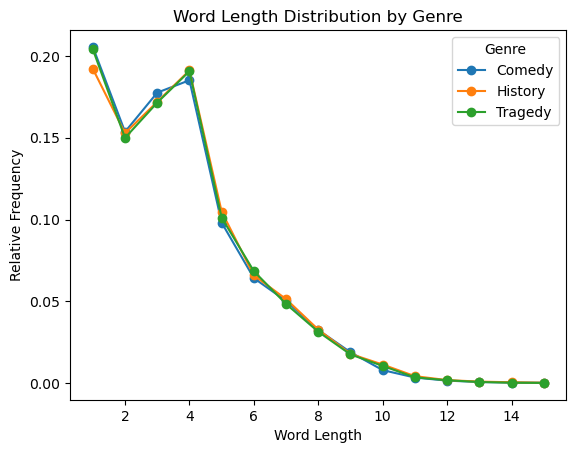

In [592]:


genres = ("Comedy", "History", "Tragedy")

# Transform the authors' corpora into lists of word tokens
play_by_genre_tokens = {}
play_by_genre_length_distributions = {}
plt.figure
for genre in genres:
    tokens = nltk.word_tokenize(play_by_genre[genre])

    # Filter out punctuation
    play_by_genre_tokens[genre] = ([token for token in tokens
                                            if any(c.isalpha() for c in token)])

    token_lengths = [len(token) for token in tokens]
    freq_dist = nltk.FreqDist(token_lengths)
    
    
    lengths = sorted(freq_dist.keys())[:15]
    frequencies = [freq_dist.freq(length) for length in lengths]

    plt.plot(
        lengths,
        frequencies,
        marker='o',
        label=genre)

# Format the single graph
plt.title("Word Length Distribution by Genre")
plt.xlabel("Word Length")
plt.ylabel("Relative Frequency")

# Add the key
plt.legend(title="Genre")


We can see from this graph that there is little variation. This is slightly predictable as it was Mendenhall's theory that an author's characteristic curve of composition taken from any large enough sample of their work would stay constant for their entire career.

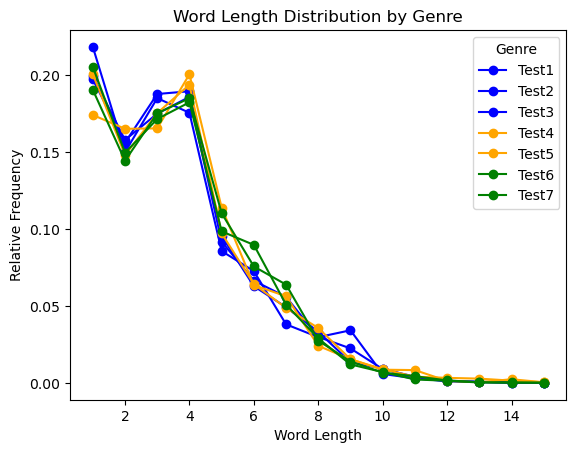

In [595]:
genres = ("Test1", "Test2", "Test3", "Test4", "Test5", "Test6", "Test7")

# Transform the authors' corpora into lists of word tokens
play_by_genre_tokens = {}
play_by_genre_length_distributions = {}
plt.figure
for genre in genres:
    tokens = nltk.word_tokenize(play_by_genre[genre])

    # Filter out punctuation
    play_by_genre_tokens[genre] = ([token for token in tokens
                                            if any(c.isalpha() for c in token)])

    token_lengths = [len(token) for token in tokens]
    freq_dist = nltk.FreqDist(token_lengths)
    
    
    lengths = sorted(freq_dist.keys())[:15]
    frequencies = [freq_dist.freq(length) for length in lengths]

    if genre in ["Test1", "Test2","Test3"]:
        c='b'
    elif genre in["Test4", "Test5"]:
        c='orange'
    else:
        c='g'

    plt.plot(
        lengths,
        frequencies,
        marker='o',
        label=genre,
        color=c)

# Format the single graph
plt.title("Word Length Distribution by Genre")
plt.xlabel("Word Length")
plt.ylabel("Relative Frequency")

# Add the key
plt.legend(title="Genre")

 Tragedy seems to have slightly less 2 letter words while comedies may tend to have more 3 letter words.However, for the most part, this seems to point to word length frequency having little to no predictive power.

## Second Method of Testing for Stylometric Differences: Kilgariff’s Chi-Squared Method
In this method chi-squared is used to measure the distance between vocabulary used in different sets of text.
It is calculated by by summing, over the n most common words, the squares of the differences between the actual numbers of tokens found in each author’s corpus and the expected numbers, divided by the expected numbers. In this case I used the 250 most common words.
The smaller the chi-squared value the more similar the vocabulary is between the two corpora.

In [599]:
genres = ("Comedy", "Tragedy", "History","Test1", "Test2", "Test3","Test4", "Test5", "Test6", "Test7")

# Transform the authors' corpora into lists of word tokens
play_by_genre_tokens = {}
play_by_genre_length_distributions = {}
plt.figure
for genre in genres:
    tokens = nltk.word_tokenize(play_by_genre[genre])

    # Filter out punctuation
    play_by_genre_tokens[genre] = ([token for token in tokens
                                            if any(c.isalpha() for c in token)])

    token_lengths = [len(token) for token in tokens]
    freq_dist = nltk.FreqDist(token_lengths)
    
    
    lengths = sorted(freq_dist.keys())[:15]
    frequencies = [freq_dist.freq(length) for length in lengths]

In [600]:
# Which are the genres we are analyzing?
genres = ("Comedy", "History", "Tragedy")
tests = ("Test1", "Test2", "Test3", "Test4", "Test5", "Test6", "Test7")

for test in tests:
# Lowercase the tokens so that the same word, capitalized or not,
# counts as one word
    for genre in genres:
        play_by_genre_tokens[genre] = (
            [token.lower() for token in play_by_genre_tokens[genre]])
    play_by_genre_tokens[test] = (
        [token.lower() for token in play_by_genre_tokens[test]])

    print(test)
    # Calculate chisquared for each of the candidate genres
    for genre in genres:
    
        # First, build a joint corpus and identify the 500 most frequent words in it
        joint_corpus = (play_by_genre_tokens[genre] +
                        play_by_genre_tokens[test])
        joint_freq_dist = nltk.FreqDist(joint_corpus)
        most_common = list(joint_freq_dist.most_common(350))
    
        # What proportion of the joint corpus is made up
        # of the candidate genre's tokens?
        genre_share = (len(play_by_genre_tokens[genre])
                        / len(joint_corpus))
    
        # Now, let's look at the 500 most common words in the candidate
        # genre's corpus and compare the number of times they can be observed
        # to what would be expected if the genre's papers
        # and the test papers were both random samples from the same distribution.
        chisquared = 0
        for word,joint_count in most_common:
    
            # How often do we really see this common word?
            genre_count = play_by_genre_tokens[genre].count(word)
            test_count = play_by_genre_tokens[test].count(word)
    
            # How often should we see it?
            expected_genre_count = joint_count * genre_share
            expected_test_count = joint_count * (1-genre_share)
    
            # Add the word's contribution to the chi-squared statistic
            chisquared += ((genre_count-expected_genre_count) *
                           (genre_count-expected_genre_count) /
                           expected_genre_count)
    
            chisquared += ((test_count-expected_test_count) *
                           (test_count-expected_test_count)
                           / expected_test_count)
        print("The Chi-squared statistic for", test, "and candidate", genre, "is", chisquared)

    print(" ")

Test1
The Chi-squared statistic for Test1 and candidate Comedy is 9638.411878813436
The Chi-squared statistic for Test1 and candidate History is 9293.00858215282
The Chi-squared statistic for Test1 and candidate Tragedy is 8258.56040141825
 
Test2
The Chi-squared statistic for Test2 and candidate Comedy is 12324.169287919989
The Chi-squared statistic for Test2 and candidate History is 12497.505779363499
The Chi-squared statistic for Test2 and candidate Tragedy is 13034.214813221168
 
Test3
The Chi-squared statistic for Test3 and candidate Comedy is 8655.089498548172
The Chi-squared statistic for Test3 and candidate History is 13259.38335191861
The Chi-squared statistic for Test3 and candidate Tragedy is 12496.528527188471
 
Test4
The Chi-squared statistic for Test4 and candidate Comedy is 5892.618441783395
The Chi-squared statistic for Test4 and candidate History is 5125.220234165811
The Chi-squared statistic for Test4 and candidate Tragedy is 8331.205254422108
 
Test5
The Chi-squared 

Correct: 7/7 

Guidlines for choosing n:
"scholars have suggested between 100 and 1,000 of the most common words; one project even used every word that appeared in the corpus at least twice. As a guideline, the larger the corpus, the larger the number of words that can be used as features without running the risk of giving undue importance to a word that occurs only a handful of times." (Introduction to Stylometry With Python, François Dominic Laramée)
I tested 100, 200, 250, 300, 500, 1000. 250 and 300 words gave me the highest accuracy.
 This could make sense with the size of the data set. While not super small, each test is only one play so it is definitely on the smaller size.

## Third Method of Testing for Stylometric Differences: John Burrows’ Delta Method
Burrows' Delta is designed to compare how a certain text and an arbitrary amount of sets of texts diverge from the average of them all put together.
It ends up taking the average of the absolute values of the differences between the z-scores for each feature between the anonymous paper and the candidate subcorpus.
The winning candidate is the genre for whom the delta score between the genre's subcorpus and the test case is the lowest.

The Delta Method gives equal weight to every feature that it measures, thus avoiding the problem of common words overwhelming the results, which was an issue with chi-squared tests.

In [606]:
# Who are we dealing with this time?
genres = ("History", "Tragedy", "Comedy", "Test1", "Test2", "Test3", "Test4", "Test5", "Test6", "Test7")

# Convert papers to lowercase to count all tokens of the same word together
# regardless of case
for genre in genres:
    play_by_genre_tokens[genre] = (
        [tok.lower() for tok in play_by_genre_tokens[genre]])


whole_corpus = []
for genre in genres:
    whole_corpus += play_by_genre_tokens[genre]

# Get a frequency distribution
whole_corpus_freq_dist = list(nltk.FreqDist(whole_corpus).most_common(20))
whole_corpus_freq_dist[ :10 ]

[('the', 28926),
 ('and', 26640),
 ('i', 23242),
 ('to', 19575),
 ('of', 17670),
 ('a', 15061),
 ('you', 14511),
 ('my', 12725),
 ('that', 11500),
 ('in', 11153)]

These are our 10 most frequent words in the full corpus

In [609]:
# The main data structure
features = [word for word,freq in whole_corpus_freq_dist]
feature_freqs = {}

for genre in genres:
    # A dictionary for each candidate's features
    feature_freqs[genre] = {}

    # A helper value containing the number of tokens in the genre's subcorpus
    overall = len(play_by_genre_tokens[genre])

    # Calculate each feature's presence in the subcorpus
    for feature in features:
        presence = play_by_genre_tokens[genre].count(feature)
        feature_freqs[genre][feature] = presence / overall

In [611]:
import math

# The data structure into which we will be storing the "corpus standard" statistics
corpus_features = {}

# For each feature...
for feature in features:
    # Create a sub-dictionary that will contain the feature's mean
    # and standard deviation
    corpus_features[feature] = {}

    # Calculate the mean of the frequencies expressed in the subcorpora
    feature_average = 0
    for genre in genres:
        feature_average += feature_freqs[genre][feature]
    feature_average /= len(genres)
    corpus_features[feature]["Mean"] = feature_average

    # Calculate the standard deviation using the basic formula for a sample
    feature_stdev = 0
    for genre in genres:
        diff = feature_freqs[genre][feature] - corpus_features[feature]["Mean"]
        feature_stdev += diff*diff
    feature_stdev /= (len(genres) - 1)
    feature_stdev = math.sqrt(feature_stdev)
    corpus_features[feature]["StdDev"] = feature_stdev

In [613]:
feature_zscores = {}
for genre in genres:
    feature_zscores[genre] = {}
    for feature in features:

        # Z-score definition = (value - mean) / stddev
        # We use intermediate variables to make the code easier to read
        feature_val = feature_freqs[genre][feature]
        feature_mean = corpus_features[feature]["Mean"]
        feature_stdev = corpus_features[feature]["StdDev"]
        feature_zscores[genre][feature] = ((feature_val-feature_mean) /
                                            feature_stdev)

In [615]:
# Tokenize the test case
testcase_tokens = nltk.word_tokenize(play_by_genre["Test1"])

# Filter out punctuation and lowercase the tokens
testcase_tokens = [token.lower() for token in testcase_tokens
                   if any(c.isalpha() for c in token)]

# Calculate the test case's features
overall = len(testcase_tokens)
testcase_freqs = {}
for feature in features:
    presence = testcase_tokens.count(feature)
    testcase_freqs[feature] = presence / overall

# Calculate the test case's feature z-scores
testcase_zscores = {}
for feature in features:
    feature_val = testcase_freqs[feature]
    feature_mean = corpus_features[feature]["Mean"]
    feature_stdev = corpus_features[feature]["StdDev"]
    testcase_zscores[feature] = (feature_val - feature_mean) / feature_stdev
    print("Test case z-score for feature", feature, "is", testcase_zscores[feature])

Test case z-score for feature the is -0.2289715945413032
Test case z-score for feature and is 0.0791752161434511
Test case z-score for feature i is 1.5532975798697388
Test case z-score for feature to is -0.8972891161858926
Test case z-score for feature of is -0.09909397199154381
Test case z-score for feature a is 1.1189459961376256
Test case z-score for feature you is 1.0885333242951518
Test case z-score for feature my is -0.6489395720052575
Test case z-score for feature that is 1.9000468183064694
Test case z-score for feature in is 1.8678003635306153
Test case z-score for feature is is 1.18368093859217
Test case z-score for feature not is 1.282078875035175
Test case z-score for feature me is 1.07927563504882
Test case z-score for feature it is -0.15546807763378942
Test case z-score for feature with is -0.13122820508025812
Test case z-score for feature 's is -1.1543602210720003
Test case z-score for feature for is 0.5989480261021473
Test case z-score for feature be is 0.504942050743209

In [617]:
tests = ("Test1", "Test2", "Test3", "Test4", "Test5", "Test6", "Test7")
for test in tests:
    print(test)
    # Tokenize the test case
    testcase_tokens = nltk.word_tokenize(play_by_genre[test])
    
    # Filter out punctuation and lowercase the tokens
    testcase_tokens = [token.lower() for token in testcase_tokens
                       if any(c.isalpha() for c in token)]
    
    # Calculate the test case's features
    overall = len(testcase_tokens)
    testcase_freqs = {}
    for feature in features:
        presence = testcase_tokens.count(feature)
        testcase_freqs[feature] = presence / overall
    
    # Calculate the test case's feature z-scores
    testcase_zscores = {}
    for feature in features:
        feature_val = testcase_freqs[feature]
        feature_mean = corpus_features[feature]["Mean"]
        feature_stdev = corpus_features[feature]["StdDev"]
        testcase_zscores[feature] = (feature_val - feature_mean) / feature_stdev
        
    for genre in genres:
        delta = 0
        for feature in features:
            delta += math.fabs((testcase_zscores[feature] -
                                feature_zscores[genre][feature]))
        delta /= len(features)
        print( "Delta score for", test, "and candidate", genre, "is", delta )
    print(" ")

Test1
Delta score for Test1 and candidate History is 1.269229452512254
Delta score for Test1 and candidate Tragedy is 1.098408253463023
Delta score for Test1 and candidate Comedy is 0.7573992753080779
Delta score for Test1 and candidate Test1 is 0.0
Delta score for Test1 and candidate Test2 is 1.0725140041237828
Delta score for Test1 and candidate Test3 is 1.0330376340838199
Delta score for Test1 and candidate Test4 is 1.1465872885963129
Delta score for Test1 and candidate Test5 is 1.8186567864693626
Delta score for Test1 and candidate Test6 is 0.8834041835187684
Delta score for Test1 and candidate Test7 is 1.4387657747912805
 
Test2
Delta score for Test2 and candidate History is 1.4220847619068266
Delta score for Test2 and candidate Tragedy is 1.0619317883363169
Delta score for Test2 and candidate Comedy is 0.9714528932647524
Delta score for Test2 and candidate Test1 is 1.0725140041237828
Delta score for Test2 and candidate Test2 is 0.0
Delta score for Test2 and candidate Test3 is 1.3

Correct: 6/7
Test6, which was Julius Caesar, has a delta score of .8010 for comedy and a delta score of .8124 for tragedy. Under the delta method it is classified as comedy but it is assigned a similar difference from both comedy and tragedy.

To do a bit of further analysis I calculated the z-scores for each genre and the 20 most frequent words.

In [621]:
# Tokenize the test case
testcase_tokens = nltk.word_tokenize(play_by_genre["Comedy"])

# Filter out punctuation and lowercase the tokens
testcase_tokens = [token.lower() for token in testcase_tokens
                   if any(c.isalpha() for c in token)]

# Calculate the test case's features
overall = len(testcase_tokens)
testcase_freqs = {}
for feature in features:
    presence = testcase_tokens.count(feature)
    testcase_freqs[feature] = presence / overall

# Calculate the test case's feature z-scores
testcase_zscores = {}
for feature in features:
    feature_val = testcase_freqs[feature]
    feature_mean = corpus_features[feature]["Mean"]
    feature_stdev = corpus_features[feature]["StdDev"]
    testcase_zscores[feature] = (feature_val - feature_mean) / feature_stdev
    print("Test case z-score for feature", feature, "is", testcase_zscores[feature])

Test case z-score for feature the is -0.25718855260125434
Test case z-score for feature and is -1.2222777747298392
Test case z-score for feature i is 0.8624952348036443
Test case z-score for feature to is -0.5398958967187176
Test case z-score for feature of is -0.13606924003305573
Test case z-score for feature a is 0.5646872560881055
Test case z-score for feature you is 0.1980421602795453
Test case z-score for feature my is 0.18462898710887476
Test case z-score for feature that is -0.08245079874771767
Test case z-score for feature in is -0.024110174939728946
Test case z-score for feature is is 0.1484951205877881
Test case z-score for feature not is 0.35298215761332113
Test case z-score for feature me is 0.6026368215817375
Test case z-score for feature it is 0.3075593643716861
Test case z-score for feature with is -0.9911647217116532
Test case z-score for feature 's is 0.18056647024242392
Test case z-score for feature for is 0.3168734145127493
Test case z-score for feature be is 0.08564

In [622]:
# Tokenize the test case
testcase_tokens = nltk.word_tokenize(play_by_genre["History"])

# Filter out punctuation and lowercase the tokens
testcase_tokens = [token.lower() for token in testcase_tokens
                   if any(c.isalpha() for c in token)]

# Calculate the test case's features
overall = len(testcase_tokens)
testcase_freqs = {}
for feature in features:
    presence = testcase_tokens.count(feature)
    testcase_freqs[feature] = presence / overall

# Calculate the test case's feature z-scores
testcase_zscores = {}
for feature in features:
    feature_val = testcase_freqs[feature]
    feature_mean = corpus_features[feature]["Mean"]
    feature_stdev = corpus_features[feature]["StdDev"]
    testcase_zscores[feature] = (feature_val - feature_mean) / feature_stdev
    print("Test case z-score for feature", feature, "is", testcase_zscores[feature])

Test case z-score for feature the is 0.49955428429399207
Test case z-score for feature and is 0.6820738784243573
Test case z-score for feature i is -0.6612832955259087
Test case z-score for feature to is -0.22721673197348208
Test case z-score for feature of is 0.6284649878908206
Test case z-score for feature a is -0.4466753901007128
Test case z-score for feature you is -0.9315821618474616
Test case z-score for feature my is 0.4899523279703374
Test case z-score for feature that is -0.30306183147999005
Test case z-score for feature in is 0.6136565146125353
Test case z-score for feature is is -1.678440195325424
Test case z-score for feature not is -1.3167595685477231
Test case z-score for feature me is -0.5475044195567156
Test case z-score for feature it is -1.1825624171672608
Test case z-score for feature with is 0.06111115051857745
Test case z-score for feature 's is -0.08256225332448452
Test case z-score for feature for is -0.0011358711106567141
Test case z-score for feature be is -0.1

In [625]:
# Tokenize the test case
testcase_tokens = nltk.word_tokenize(play_by_genre["Tragedy"])

# Filter out punctuation and lowercase the tokens
testcase_tokens = [token.lower() for token in testcase_tokens
                   if any(c.isalpha() for c in token)]

# Calculate the test case's features
overall = len(testcase_tokens)
testcase_freqs = {}
for feature in features:
    presence = testcase_tokens.count(feature)
    testcase_freqs[feature] = presence / overall

# Calculate the test case's feature z-scores
testcase_zscores = {}
for feature in features:
    feature_val = testcase_freqs[feature]
    feature_mean = corpus_features[feature]["Mean"]
    feature_stdev = corpus_features[feature]["StdDev"]
    testcase_zscores[feature] = (feature_val - feature_mean) / feature_stdev
    print("Test case z-score for feature", feature, "is", testcase_zscores[feature])

Test case z-score for feature the is -0.04524655438348591
Test case z-score for feature and is -0.6704046438721122
Test case z-score for feature i is -0.3860678881835958
Test case z-score for feature to is -0.017996481201065336
Test case z-score for feature of is -0.49204216620188956
Test case z-score for feature a is -0.40769366633786003
Test case z-score for feature you is -0.2282938059166529
Test case z-score for feature my is 0.16466083783449148
Test case z-score for feature that is -0.043310450768533966
Test case z-score for feature in is -0.28199699884040297
Test case z-score for feature is is -0.6094077020949683
Test case z-score for feature not is 0.12416027423498317
Test case z-score for feature me is -0.22006667510618003
Test case z-score for feature it is 0.14036231167424076
Test case z-score for feature with is 0.08715627086979162
Test case z-score for feature 's is 0.5577568593084071
Test case z-score for feature for is -0.5466173512976851
Test case z-score for feature be 

I then looked to see which z-scores had an absolute value greater than 0.75. This demonstrated some words each genre used more ‘abnormally’.


##### Comedy:
and is -1.2222777747298392 \
i is 0.8624952348036443 \
with is -0.9911647217116532

##### History:
you is -0.9315821618474616 \
is is -1.678440195325424 \
not is -1.3167595685477231 \
it is -1.1825624171672608 \
his is 0.9839694634869856

##### Tragedy:
be is -0.8215327168620244


While we do not really know what is causing these values, there are possibilities. Shakespeare is known for comedic monlogues which may account for the heavier use of "i". Additionaly all of the histories center on a male character which is likely the reason for the increased prevelance of "his". 

Ultimately, I was able to use methods designed to identify authorship to prove that there is a stylistic difference between Shakespeare's comedies, histories, and tragedies. The genres seemed not to have varied very distinctly when observing Mendenhall's characteristic curves of composition, which displays the frequency of words of certain lengths. However, while Shakespeare kept the length of words somewhat constant, the genres do seem distinguishable when looking at vocabulary. 

Sources: \
The Complete Works of William Shakespeare. https://shakespeare.mit.edu/index.html \
Laramée, François Dominic. Introduction to Stylometry with Python. https://doi.org/10.46430/phen0078